<div align="center">
  <img src="https://capsule-render.vercel.app/api?type=waving&color=0:0f2027,50:203a43,100:2c5364&height=200&section=header&text=Deep%Learning%20Projet&fontSize=50&fontColor=ffffff&animation=fadeIn&fontAlignY=38&desc=Fall%20Semester%202026/2027&descAlignY=58&descSize=18" width="100%" alt="banner"/>
</div>

<h2 align="center">Team</h2>

<table align="center">
  <tr>
    <td align="center">
      <a href="https://github.com/USER0">
        <img src="https://github.com/USER0.png" width="100" style="border-radius:50%" alt="Nome 0"/><br/>
        <b>Carlota Marto 20241729</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/DiogoCapelaGoncalves">
        <img src="https://github.com/DiogoCapelaGoncalves.png" width="100" style="border-radius:50%" alt="Nome 1"/><br/>
        <b>Diogo Capela 20241817</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/USER2">
        <img src="https://github.com/USER2.png" width="100" style="border-radius:50%" alt="Nome 2"/><br/>
        <b>Henrique Santos 20241752</b>
    <td align="center">
      <a href="https://github.com/USER4">
        <img src="https://github.com/USER4.png" width="100" style="border-radius:50%" alt="Nome 4"/><br/>
        <b>Laura Lisboa 20241783</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/tiago2806">
        <img src="https://github.com/tiago2806.png" width="100" style="border-radius:50%" alt="Nome 5"/><br/>
        <b>Homo Maximus 20241728</b>
      </a>
    </td>
  </tr>
</table>

<table align="center">
  <tr>
    <th>Índice</th>
  </tr>
  <tr>
    <td><a href="#sobre">1. Sobre</a></td>
  </tr>
  <tr>
    <td><a href="#instalação">2. Instalação</a></td>
  </tr>
  <tr>
    <td><a href="#utilização">3. Utilização</a></td>
  </tr>
  <tr>
    <td><a href="#resultados">4. Resultados</a></td>
  </tr>
  <tr>
    <td><a href="#equipa">5. Equipa</a></td>
  </tr>
</table>

Imports

In [9]:
%pip install tensorboard

   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ------------- -------------------------- 1.8/5.5 MB 9.6 MB/s eta 0:00:01
   ------------------------------ --------- 4.2/5.5 MB 10.5 MB/s eta 0:00:01
   ---------------------------------------- 5.5/5.5 MB 10.5 MB/s  0:00:00

   ---------------------------------------- 0/4 [werkzeug]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboard]
   ------------------------------ --------- 3/4 [tensorboard]
   ---------------------------------------- 4/4 [tensorboard]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [10]:
import os
import sys
import json
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report
from tensorflow.keras import Sequential, layers, regularizers, callbacks

sys.path.insert(0, str(Path("..").resolve()))
from utils.preprocessing_functions import images_to_tensor_batches

tf.keras.utils.set_random_seed(42)

In [11]:
DATA = "../Data"
path = f"{DATA}/Tiny_ImageNet_Project_2026_Students/images"
BATCH_SIZE = 64

os.makedirs("../Models", exist_ok=True)
os.makedirs("../logs", exist_ok=True)

In [12]:
train_df = pd.read_csv(f"{DATA}/train_labels.csv")
val_df   = pd.read_csv(f"{DATA}/val_labels.csv")
test_df  = pd.read_csv(f"{DATA}/test_labels.csv")

print(len(train_df), len(val_df), len(test_df))

class_names = json.load(open(f"{DATA}/class_names.json"))
class_to_idx = {c: i for i, c in enumerate(class_names)}

y_train = train_df["description"].map(class_to_idx).values
y_val   = val_df["description"].map(class_to_idx).values
y_test  = test_df["description"].map(class_to_idx).values

# JSON keys are strings, Keras needs integers
class_weights = {int(k): v for k, v in json.load(open(f"{DATA}/class_weights.json")).items()}

40794 8998 8998


In [13]:
train_ds = images_to_tensor_batches(train_df["filename"], y_train, path, BATCH_SIZE, training=True)
val_ds   = images_to_tensor_batches(val_df["filename"],   y_val,   path, BATCH_SIZE)
test_ds  = images_to_tensor_batches(test_df["filename"],  y_test,  path, BATCH_SIZE)

for images, labels_batch in train_ds.take(1):
    print(images.shape, images.numpy().min(), images.numpy().max())

(64, 64, 64, 3) 0.0 1.0


In [14]:
class RandomBlur(layers.Layer):
    def __init__(self, probability=0.3, **kwargs):
        super().__init__(**kwargs)
        self.probability = probability
        k = tf.constant([1., 2., 1.])
        kernel = tf.tensordot(k, k, axes=0)
        kernel = kernel / tf.reduce_sum(kernel)
        self.kernel = tf.tile(kernel[:, :, None, None], [1, 1, 3, 1])

    def call(self, images, training=None):
        if not training:
            return images
        blurred = tf.nn.depthwise_conv2d(images, self.kernel, strides=[1, 1, 1, 1], padding="SAME")
        apply = tf.random.uniform([tf.shape(images)[0], 1, 1, 1]) < self.probability
        return tf.where(apply, blurred, images)


class RandomNoise(layers.Layer):
    def __init__(self, stddev=0.03, **kwargs):
        super().__init__(**kwargs)
        self.stddev = stddev

    def call(self, images, training=None):
        if not training:
            return images
        noisy = images + tf.random.normal(tf.shape(images), stddev=self.stddev)
        return tf.clip_by_value(noisy, 0.0, 1.0)


data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    RandomBlur(probability=0.3),
    RandomNoise(stddev=0.03),
], name="data_augmentation")

In [15]:
model = Sequential([
    layers.Input((64, 64, 3)),
    data_augmentation,                      # only active during training
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, kernel_regularizer=regularizers.l2(0.001), activation="relu"),
    layers.Dense(200, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 200)            │        25,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,650,952 (6.30 MB)

 Trainable params: 1,650,952 (6.30 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
run_name = "baseline_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    callbacks.ModelCheckpoint(f"../Models/{run_name}.keras", monitor="val_loss", save_best_only=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    callbacks.TensorBoard(log_dir=f"../logs/{run_name}"),
]

In [17]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    class_weight=class_weights,
    callbacks=cbs,
)

Epoch 1/60


c:\Users\diogo\anaconda3\envs\NOVAIMS\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


638/638 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.0228 - loss: 5.2027 - val_accuracy: 0.0316 - val_loss: 5.0680 - learning_rate: 0.0010
Epoch 2/60
638/638 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.0452 - loss: 5.0187 - val_accuracy: 0.0538 - val_loss: 4.9179 - learning_rate: 0.0010
Epoch 3/60
638/638 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.0619 - loss: 4.8964 - val_accuracy: 0.0701 - val_loss: 4.8233 - learning_rate: 0.0010
Epoch 4/60
638/638 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.0726 - loss: 4.8153 - val_accuracy: 0.0796 - val_loss: 4.7508 - learning_rate: 0.0010
Epoch 5/60
638/638 ━━━━━━━━━━━━━━━━━━━━ 22s 34ms/step - accuracy: 0.0832 - loss: 4.7515 - val_accuracy: 0.0921 - val_loss: 4.6752 - learning_rate: 0.0010
Epoch 6/60
638/638 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.0895 - loss: 4.6987 - val_accuracy: 0.0898 - val_loss: 4.6526 - learning_rate: 0.0010
Epoch 7/60
638/638 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.0972 - loss: 4.6507

In [18]:
%load_ext tensorboard
%tensorboard --logdir ../logs

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

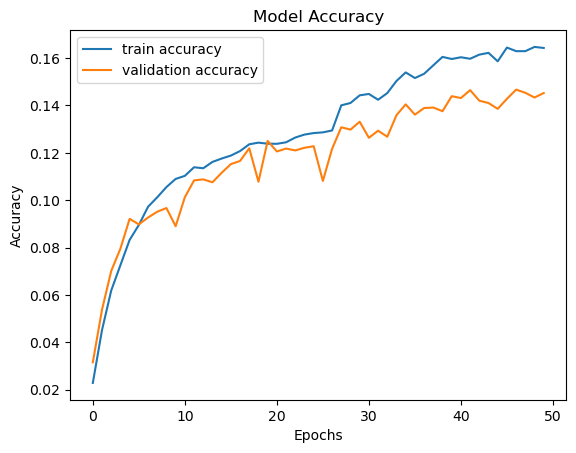

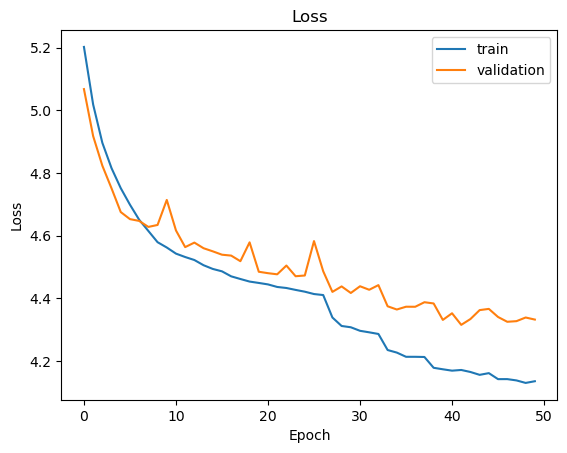

In [19]:
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [20]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_pred = model.predict(test_ds).argmax(axis=1)
print("Macro-F1:", f1_score(y_test, y_pred, average="macro"))

141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.1349 - loss: 4.3804
Test accuracy: 0.1349
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Macro-F1: 0.10076832129045765


In [21]:
report = classification_report(y_test, y_pred, target_names=[c.split(",")[0] for c in class_names],
                               output_dict=True, zero_division=0)
per_class = (pd.DataFrame(report).T.iloc[:200]
             .sort_values("f1-score")[["precision", "recall", "f1-score", "support"]])
per_class.head(15)

,precision,recall,f1-score,support
African elephant,0.0,0.0,0.0,21.0
oboe,0.0,0.0,0.0,78.0
mushroom,0.0,0.0,0.0,19.0
mashed potato,0.0,0.0,0.0,18.0
wok,0.0,0.0,0.0,32.0
hog,0.0,0.0,0.0,29.0
grasshopper,0.0,0.0,0.0,18.0
goose,0.0,0.0,0.0,19.0
gasmask,0.0,0.0,0.0,78.0
dumbbell,0.0,0.0,0.0,49.0
